# DS471 Breast Cancer Classification
**Group members:** [Name and ID 1], [Name and ID 2], [Name and ID 3], [optional Name and ID 4]. **CRN:** [CRN].

Educational classification of malignant versus benign breast masses using the approved UCI Wisconsin Diagnostic dataset. This is a retrospective benchmark, not a clinical diagnostic tool.

Run all cells in order with Python 3.12, numpy 2.3.5, pandas 2.2.3, scipy 1.17.0, scikit-learn 1.8.0 and matplotlib 3.10.8 (actual runtime versions printed below). The dataset is bundled with scikit-learn, so no download or credentials are needed. Install packages with `pip install numpy pandas scipy scikit-learn matplotlib` if absent. All tables and figures are regenerated in `results/`.

The project uses real observations, not synthetic data. The scikit-learn copy omits source record IDs. Its target is reversed below so **malignant = 1**, benign = 0. A single stratified 60/20/20 split is fixed before exploratory modeling. Only the training portion informs EDA and feature rankings.

In [1]:
from pathlib import Path
import sys, json, copy, hashlib, platform
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
 roc_auc_score, confusion_matrix, log_loss, roc_curve)
OUT=Path('results'); OUT.mkdir(exist_ok=True)
SEED=42
versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
 'scipy':scipy.__version__,'scikit-learn':sklearn.__version__,'matplotlib':matplotlib.__version__}
print(json.dumps(versions,indent=2))
plt.rcParams.update({'figure.dpi':120,'font.size':10})
def savefig(name):
 plt.tight_layout(); plt.savefig(OUT/name,dpi=180,bbox_inches='tight'); plt.show(); plt.close()
def table(df,name):
 df.to_csv(OUT/name,index=False); print(df.to_string(index=False))


{
  "python": "3.12.14",
  "numpy": "2.3.5",
  "pandas": "2.2.3",
  "scipy": "1.17.0",
  "scikit-learn": "1.8.0",
  "matplotlib": "3.10.8"
}


## Stage 1 Data cleaning preparation and exploration
### Data definition and integrity
UCI reports 569 records and 30 continuous predictors extracted from fine needle aspirate images (Wolberg et al., 1993). Ten measurements describe radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry and fractal dimension. Each has a mean, standard error and worst summary; “worst” means the mean of the three largest values, not a diagnosis. Diagnosis is categorical. No demographic information is supplied. The bundled loader documents the dataset schema (scikit-learn developers, n.d.-b).

Check nulls, infinities, duplicate predictor rows, constant features, negative measurements and target membership before splitting. No imputation or row removal is applied when these checks pass. These structural checks do not estimate predictive relationships. The feature matrix fingerprint below records the exact bundled data used.

In [2]:
raw=load_breast_cancer(as_frame=True)
X=raw.data.copy(); y=(raw.target==0).astype(int).rename('malignant')
audit={'rows':len(X),'predictors':X.shape[1],'missing':int(X.isna().sum().sum()),
 'infinite':int(np.isinf(X).sum().sum()),'duplicate_predictor_rows':int(X.duplicated().sum()),
 'constant_features':int((X.nunique()==1).sum()),'negative_values':int((X<0).sum().sum()),
 'benign':int((y==0).sum()),'malignant':int(y.sum()),'feature_dtype':str(X.dtypes.unique()),
 'sha256_float64_C_order':hashlib.sha256(X.to_numpy(dtype='<f8').tobytes()).hexdigest()}
assert X.shape==(569,30) and set(y.unique())=={0,1}
assert audit['missing']==audit['infinite']==audit['duplicate_predictor_rows']==audit['constant_features']==audit['negative_values']==0
print(json.dumps(audit,indent=2))


{
  "rows": 569,
  "predictors": 30,
  "missing": 0,
  "infinite": 0,
  "duplicate_predictor_rows": 0,
  "constant_features": 0,
  "negative_values": 0,
  "benign": 357,
  "malignant": 212,
  "feature_dtype": "[dtype('float64')]",
  "sha256_float64_C_order": "6b202a2072f9a0385f405a8f8605b1b06f6f36ae6d23d9cd6cbbc0974a416bc7"
}


## Stage 2 Data splitting
Reserve 20% (114 records) as an untouched test set; split the remainder 75/25 to yield 341 training and 114 validation records. This leaves enough observations to fit compact models while preserving roughly 42 malignant cases in each holdout. Stratification maintains the target ratio and random seed 42 makes row membership reproducible. Five-fold stratified cross-validation tunes traditional models using training rows only. The separate validation set selects neural configuration and epoch and then the recommended model; the test set is opened once after these choices are fixed. No final refit is performed, so every reported model has exactly the monitored training history.

In [3]:
idx=np.arange(len(X))
itr,ite=train_test_split(idx,test_size=0.2,stratify=y,random_state=SEED)
itr,iva=train_test_split(itr,test_size=0.25,stratify=y.iloc[itr],random_state=SEED)
assert not (set(itr)&set(iva) or set(itr)&set(ite) or set(iva)&set(ite))
assert len(set(itr)|set(iva)|set(ite))==len(X)
Xtr,Xva,Xte=X.iloc[itr],X.iloc[iva],X.iloc[ite]
ytr,yva,yte=y.iloc[itr],y.iloc[iva],y.iloc[ite]
splits=pd.DataFrame([{'set':n,'n':len(i),'benign':int((y.iloc[i]==0).sum()),'malignant':int(y.iloc[i].sum())}
 for n,i in [('Training',itr),('Validation',iva),('Test',ite)]])
table(splits,'split_counts.csv')
pd.DataFrame({'row':idx,'split':['training' if i in set(itr) else 'validation' if i in set(iva) else 'test' for i in idx]}).to_csv(OUT/'split_membership.csv',index=False)


       set   n  benign  malignant
  Training 341     214        127
Validation 114      71         43
      Test 114      72         42


### Training only EDA and preprocessing decisions
Inspect class balance, feature distributions, correlations and univariate mutual information. Tukey fences flag potential outliers within training data. Keep flagged observations: unusually large cell measurements can be meaningful malignant cases, and a statistical fence does not prove an error. Nonnegative zeros are valid measurements, not automatically missing. Standard scaling addresses the large unit differences for logistic regression and the neural network. It is fitted inside each CV pipeline or on training rows only. Trees split by order and do not require scaling.

No categorical predictor encoding is necessary. Reversing the target makes all reported precision, recall and F1 values refer to malignancy. Feature engineering consists of standardized measurements for scale-sensitive models; no arbitrary ratios or polynomial terms are added because 30 supplied summaries already contain correlated information and the sample is small. All 30 features remain in the final models: relevance rankings are descriptive, not a selection step. L2 regularization and constrained forest trees manage redundancy and complexity (scikit-learn developers, n.d.-c).

                feature  count       mean        std        min        25%        50%         75%        max
            mean radius  341.0  14.163419   3.599320   6.981000  11.670000  13.340000   16.140000   27.42000
           mean texture  341.0  19.428768   4.361160   9.710000  16.390000  18.900000   21.870000   39.28000
         mean perimeter  341.0  92.172581  24.857806  43.790000  74.680000  86.100000  105.800000  186.90000
              mean area  341.0 659.691789 360.073150 143.500000 417.200000 551.100000  809.800000 2501.00000
        mean smoothness  341.0   0.095654   0.014271   0.064290   0.084730   0.095140    0.104400    0.16340
       mean compactness  341.0   0.103103   0.053278   0.023440   0.062320   0.092180    0.130400    0.34540
         mean concavity  341.0   0.087244   0.078981   0.000000   0.027120   0.058350    0.132100    0.42680
    mean concave points  341.0   0.048194   0.039362   0.000000   0.019170   0.032500    0.070170    0.20120
          mean symm

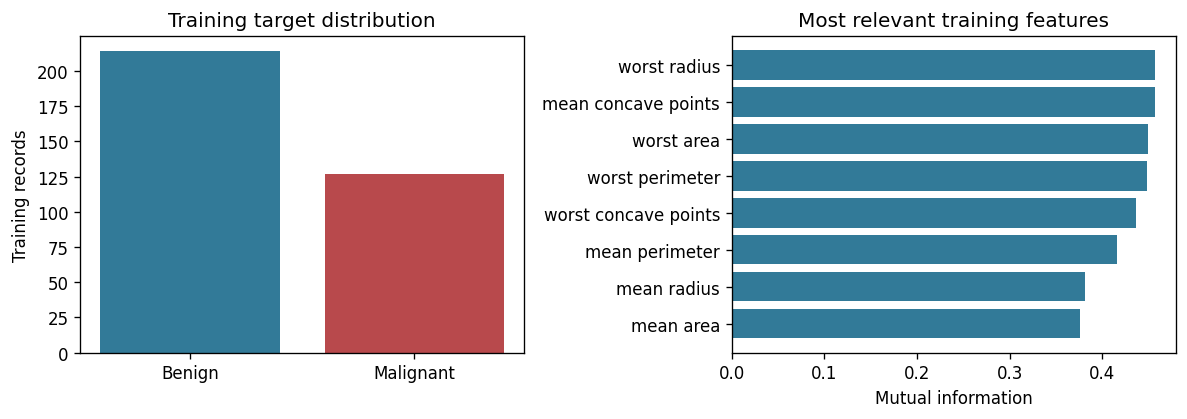

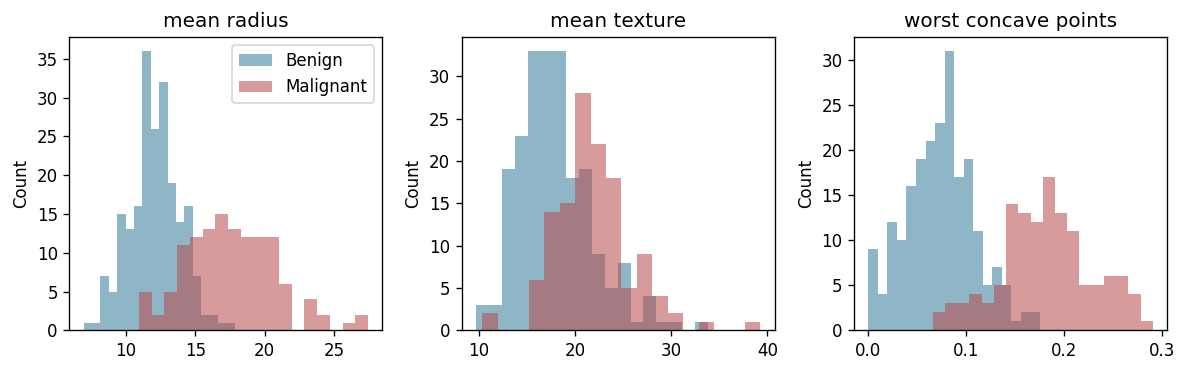

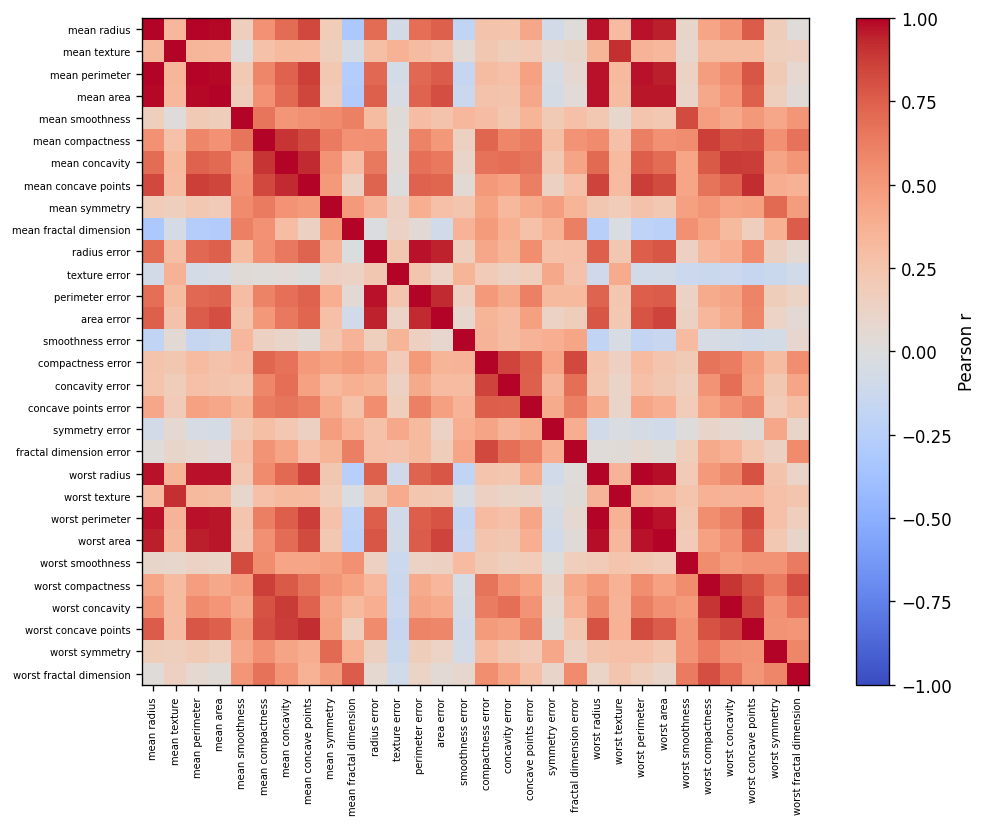

In [4]:
desc=Xtr.describe().T.reset_index(names='feature')
table(desc,'training_descriptive_statistics.csv')
q1,q3=Xtr.quantile(.25),Xtr.quantile(.75); iqr=q3-q1
flags=(Xtr.lt(q1-1.5*iqr)|Xtr.gt(q3+1.5*iqr))
outliers={'training_rows_flagged':int(flags.any(axis=1).sum()),'flagged_cells':int(flags.sum().sum())}
print('Outlier audit:',outliers)
mi=mutual_info_classif(Xtr,ytr,random_state=SEED)
rank=pd.DataFrame({'feature':X.columns,'mutual_information':mi}).sort_values('mutual_information',ascending=False)
table(rank,'feature_relevance.csv')
corr=Xtr.corr(); upper=corr.where(np.triu(np.ones(corr.shape,dtype=bool),k=1)).stack()
print('Strongest absolute correlation:',upper.abs().idxmax(),float(upper.abs().max()))
fig,ax=plt.subplots(1,2,figsize=(10,3.6))
ax[0].bar(['Benign','Malignant'],[(ytr==0).sum(),ytr.sum()],color=['#327a98','#b8494c']); ax[0].set_ylabel('Training records'); ax[0].set_title('Training target distribution')
r=rank.head(8).iloc[::-1]; ax[1].barh(r.feature,r.mutual_information,color='#327a98');ax[1].set_xlabel('Mutual information');ax[1].set_title('Most relevant training features')
savefig('eda.png')
fig,axs=plt.subplots(1,3,figsize=(10,3.2))
for ax,f in zip(axs,['mean radius','mean texture','worst concave points']):
 for c,label,color in [(0,'Benign','#327a98'),(1,'Malignant','#b8494c')]: ax.hist(Xtr.loc[ytr==c,f],bins=18,alpha=.55,label=label,color=color)
 ax.set_title(f); ax.set_ylabel('Count')
axs[0].legend(); savefig('distributions.png')
fig,ax=plt.subplots(figsize=(9,7)); im=ax.imshow(corr,cmap='coolwarm',vmin=-1,vmax=1)
ax.set_xticks(range(30),X.columns,rotation=90,fontsize=6); ax.set_yticks(range(30),X.columns,fontsize=6);fig.colorbar(im,ax=ax,label='Pearson r');savefig('correlations.png')


## Stage 3 Model selection and development
Logistic regression gives a regularized linear baseline and is suitable for a small binary dataset. Random forest models nonlinear splits and interactions and offers a contrast with scale-sensitive models. The mandatory multilayer perceptron learns nonlinear combinations through one or two small ReLU hidden layers and a sigmoid binary output. Adam minimizes regularized cross-entropy. A compact network is appropriate because only 341 rows are available for fitting. A constant benign classifier is included only as a reference and is not counted among the three models.

## Stage 4 Model training and hyperparameter optimization
GridSearchCV provides cross-validated search and refitting (scikit-learn developers, n.d.-a). Traditional grids use the same shuffled stratified five folds and mean malignant F1 as the objective. Logistic C controls inverse L2 penalty strength; class weighting tests whether compensating for the moderate imbalance helps. Forest depth and leaf size constrain variance; 200 trees stabilize the ensemble, with sqrt feature sampling.

The neural search crosses hidden widths (16 or 32–16), alpha (0.0001 or 0.01), and learning rate (0.001 or 0.003): eight candidates. Each runs 300 epochs with batch size 32. After each epoch, record *unpenalized* cross-entropy and accuracy on training and validation sets. Keep the checkpoint at minimum validation loss, then select the candidate with lowest checkpoint loss. This uses the explicit holdout for early checkpoint selection rather than MLP's internal validation split. Patience is not used; all trajectories are observed, but only the selected checkpoint is evaluated finally. Test data never enter this loop.

In [5]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
lr=Pipeline([('scale',StandardScaler()),('model',LogisticRegression(max_iter=3000,random_state=SEED))])
rf=RandomForestClassifier(n_estimators=200,max_features='sqrt',random_state=SEED,n_jobs=1)
searches={
 'Logistic regression':GridSearchCV(lr,{'model__C':[.01,.1,1,10],'model__class_weight':[None,'balanced']},cv=cv,scoring='f1',return_train_score=True,n_jobs=1),
 'Random forest':GridSearchCV(rf,{'max_depth':[3,6,None],'min_samples_leaf':[1,3,5]},cv=cv,scoring='f1',return_train_score=True,n_jobs=1)}
models={}; cv_summary=[]
for name,search in searches.items():
 search.fit(Xtr,ytr); models[name]=search.best_estimator_
 result=pd.DataFrame(search.cv_results_);result['params']=result['params'].astype(str)
 result.to_csv(OUT/(name.lower().replace(' ','_')+'_cv.csv'),index=False)
 k=search.best_index_
 cv_summary.append({'model':name,'best_parameters':str(search.best_params_),
 'CV_train_F1':search.cv_results_['mean_train_score'][k], 'CV_validation_F1':search.best_score_,
 'CV_SD':search.cv_results_['std_test_score'][k]})
table(pd.DataFrame(cv_summary),'cv_summary.csv')


              model                                      best_parameters  CV_train_F1  CV_validation_F1    CV_SD
Logistic regression {'model__C': 0.1, 'model__class_weight': 'balanced'}     0.976344          0.964833 0.022348
      Random forest           {'max_depth': None, 'min_samples_leaf': 1}     1.000000          0.932271 0.026869


                 configuration hidden_layers  alpha  learning_rate  best_epoch  validation_loss  final_validation_loss
     (16,)_alpha=0.01_lr=0.003         (16,) 0.0100          0.003          36         0.065542               0.084927
   (16,)_alpha=0.0001_lr=0.003         (16,) 0.0001          0.003          29         0.065598               0.100296
     (16,)_alpha=0.01_lr=0.001         (16,) 0.0100          0.001         109         0.065841               0.068680
   (16,)_alpha=0.0001_lr=0.001         (16,) 0.0001          0.001         104         0.065985               0.072730
  (32, 16)_alpha=0.01_lr=0.001      (32, 16) 0.0100          0.001          41         0.083853               0.107723
(32, 16)_alpha=0.0001_lr=0.001      (32, 16) 0.0001          0.001          41         0.084010               0.146075
  (32, 16)_alpha=0.01_lr=0.003      (32, 16) 0.0100          0.003          14         0.085406               0.123710
(32, 16)_alpha=0.0001_lr=0.003      (32, 16) 0.0

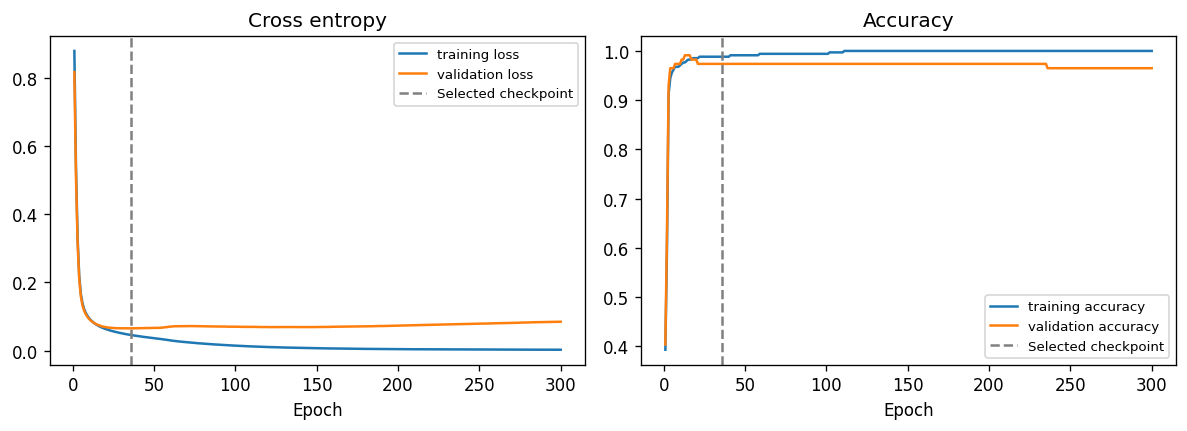

In [6]:
scaler=StandardScaler().fit(Xtr)
Ztr,Zva=scaler.transform(Xtr),scaler.transform(Xva)
records=[]; histories={}; best_loss=np.inf; best_net=None; best_key=None
for widths in [(16,),(32,16)]:
 for alpha in [.0001,.01]:
  for rate in [.001,.003]:
   key=f'{widths}_alpha={alpha}_lr={rate}'
   net=MLPClassifier(hidden_layer_sizes=widths,activation='relu',solver='adam',alpha=alpha,
       learning_rate_init=rate,batch_size=32,random_state=SEED,shuffle=True)
   hist=[]; local_loss=np.inf; checkpoint=None; epoch_best=None
   for epoch in range(1,301):
    net.partial_fit(Ztr,ytr,classes=np.array([0,1]))
    pt,pv=net.predict_proba(Ztr)[:,1],net.predict_proba(Zva)[:,1]
    lt,lv=log_loss(ytr,pt),log_loss(yva,pv)
    hist.append([epoch,lt,lv,accuracy_score(ytr,pt>=.5),accuracy_score(yva,pv>=.5)])
    if lv<local_loss:
     local_loss=lv; checkpoint=copy.deepcopy(net);epoch_best=epoch
   histories[key]=hist
   records.append({'configuration':key,'hidden_layers':str(widths),'alpha':alpha,'learning_rate':rate,
    'best_epoch':epoch_best,'validation_loss':local_loss,'final_validation_loss':hist[-1][2]})
   if local_loss<best_loss:
    best_loss=local_loss;best_net=checkpoint;best_key=key
nnsearch=pd.DataFrame(records).sort_values('validation_loss');table(nnsearch,'nn_search.csv')
models['Neural network']=Pipeline([('scale',scaler),('model',best_net)])
history=pd.DataFrame(histories[best_key],columns=['epoch','training_loss','validation_loss','training_accuracy','validation_accuracy'])
table(history.iloc[[0,int(nnsearch.iloc[0].best_epoch)-1,-1]],'nn_key_epochs.csv')
history.to_csv(OUT/'nn_history.csv',index=False)
fig,ax=plt.subplots(1,2,figsize=(10,3.7))
for a,cols,title in [(ax[0],['training_loss','validation_loss'],'Cross entropy'),(ax[1],['training_accuracy','validation_accuracy'],'Accuracy')]:
 for col in cols:a.plot(history.epoch,history[col],label=col.replace('_',' '))
 a.axvline(int(nnsearch.iloc[0].best_epoch),ls='--',color='gray',label='Selected checkpoint');a.set_xlabel('Epoch');a.set_title(title);a.legend(fontsize=8)
savefig('nn_curves.png')


### Monitor generalization and freeze the selection
The recommendation is chosen by validation malignant F1, then malignant recall, then model order (logistic first) if tied. Keep threshold 0.5 for every model; no threshold is optimized on the test set. F1 balances missed malignant cases with false alarms. Recall receives separate attention because false negatives are consequential, but this assignment does not specify a clinical cost ratio. This is an educational benchmark objective, not a clinical policy.

In [7]:
def metrics(ytrue,p):
 pred=(p>=.5).astype(int);tn,fp,fn,tp=confusion_matrix(ytrue,pred,labels=[0,1]).ravel()
 return {'accuracy':accuracy_score(ytrue,pred),'precision':precision_score(ytrue,pred,zero_division=0),
 'recall':recall_score(ytrue,pred,zero_division=0),'F1':f1_score(ytrue,pred,zero_division=0),
 'ROC_AUC':roc_auc_score(ytrue,p),'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}
monitor=[]
for name,model in models.items():
 for split,xx,yy in [('Training',Xtr,ytr),('Validation',Xva,yva)]:
  monitor.append({'model':name,'split':split,**metrics(yy,model.predict_proba(xx)[:,1])})
monitor=pd.DataFrame(monitor);table(monitor,'monitoring.csv')
v=monitor[monitor.split=='Validation'].sort_values(['F1','recall'],ascending=False,kind='stable')
champion=v.iloc[0]['model']; print('Recommendation frozen before test:',champion)


              model      split  accuracy  precision   recall       F1  ROC_AUC  TN  FP  FN  TP
Logistic regression   Training  0.985337   0.984127 0.976378 0.980237 0.995585 212   2   3 124
Logistic regression Validation  0.964912   0.953488 0.953488 0.953488 0.995414  69   2   2  41
      Random forest   Training  1.000000   1.000000 1.000000 1.000000 1.000000 214   0   0 127
      Random forest Validation  0.973684   0.976190 0.953488 0.964706 0.991648  70   1   2  41
     Neural network   Training  0.988270   0.992000 0.976378 0.984127 0.998307 213   1   3 124
     Neural network Validation  0.973684   0.954545 0.976744 0.965517 0.996069  69   2   1  42
Recommendation frozen before test: Neural network


## Stage 5 Final evaluation and comparison
Open the test set now, once for each frozen model. Accuracy measures overall correctness; precision shows how reliable malignant predictions are; recall measures malignant detection; F1 is the balanced primary comparison; ROC-AUC compares ranking across thresholds. Confusion matrices show actual error counts and avoid relying on a single score. A benign-only baseline illustrates why accuracy alone can mislead. Report a 95% Wilson interval for malignant recall because only about 42 malignant holdout cases are available. No model or epoch is changed after the following output.

              model  accuracy  precision   recall       F1  ROC_AUC  TN  FP  FN  TP
Logistic regression  0.982456   1.000000 0.952381 0.975610 0.997354  72   0   2  40
      Random forest  0.956140   0.974359 0.904762 0.938272 0.997024  71   1   4  38
     Neural network  0.973684   0.975610 0.952381 0.963855 0.996032  71   1   2  40
Always benign baseline: {'accuracy': 0.631578947368421, 'precision': 0.0, 'recall': 0.0, 'F1': 0.0, 'ROC_AUC': 0.5, 'TN': 72, 'FP': 0, 'FN': 42, 'TP': 0}
95% Wilson recall intervals: {'Logistic regression': [np.float64(0.8421014760304114), np.float64(0.9868424750910944)], 'Random forest': [np.float64(0.7793489419142897), np.float64(0.9623377511944261)], 'Neural network': [np.float64(0.8421014760304114), np.float64(0.9868424750910944)]}
Verification passed: disjoint complete split, training-only scaler, 3 models, full epoch histories, reconciled test counts and recall.


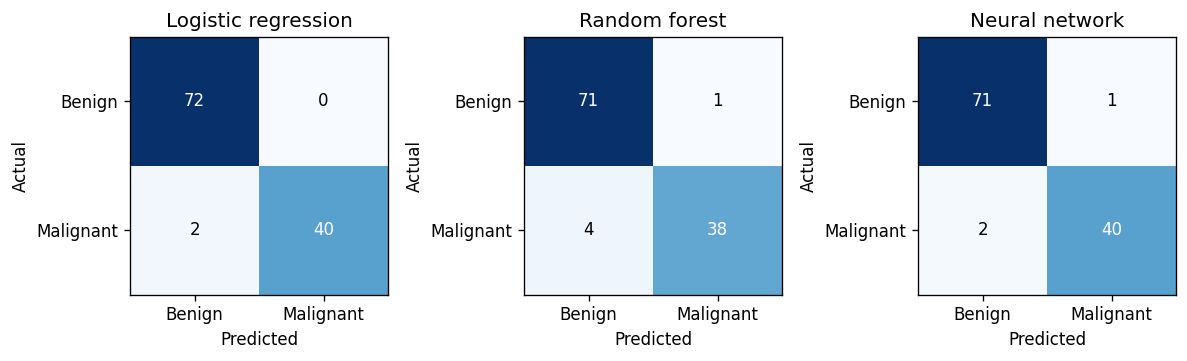

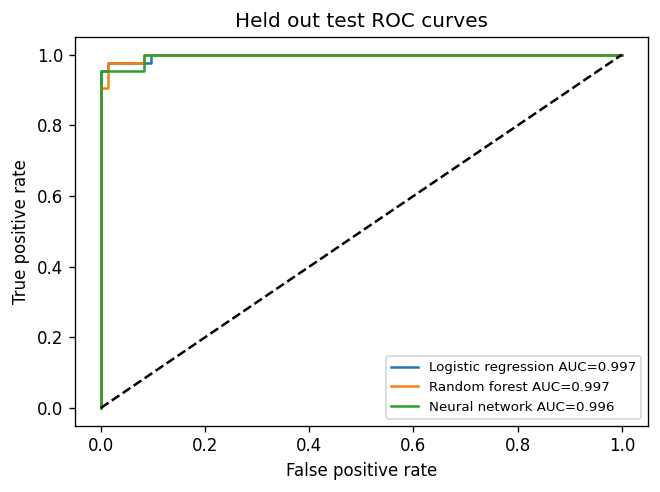

In [8]:
test_rows=[]; predictions=pd.DataFrame({'source_row':ite,'actual_malignant':yte.to_numpy()})
fig,axes=plt.subplots(1,3,figsize=(10,3.3))
figroc,axroc=plt.subplots(figsize=(5.6,4.2))
for ax,(name,model) in zip(axes,models.items()):
 prob=model.predict_proba(Xte)[:,1];m=metrics(yte,prob);test_rows.append({'model':name,**m})
 predictions[name+'_probability']=prob
 cm=confusion_matrix(yte,prob>=.5,labels=[0,1]);ax.imshow(cm,cmap='Blues')
 for (i,j),val in np.ndenumerate(cm):ax.text(j,i,str(val),ha='center',va='center',color='white' if val>cm.max()/2 else 'black')
 ax.set_xticks([0,1],['Benign','Malignant']);ax.set_yticks([0,1],['Benign','Malignant']);ax.set_xlabel('Predicted');ax.set_ylabel('Actual');ax.set_title(name)
 fpr,tpr,_=roc_curve(yte,prob);axroc.plot(fpr,tpr,label=f'{name} AUC={m["ROC_AUC"]:.3f}')
plt.figure(fig.number);savefig('confusion_matrices.png')
plt.figure(figroc.number);axroc.plot([0,1],[0,1],'k--');axroc.set(xlabel='False positive rate',ylabel='True positive rate',title='Held out test ROC curves');axroc.legend(fontsize=8);savefig('roc.png')
results=pd.DataFrame(test_rows);table(results,'test_comparison.csv');predictions.to_csv(OUT/'test_predictions.csv',index=False)
baseline=metrics(yte,np.zeros(len(yte)));print('Always benign baseline:',baseline)
def wilson(k,n,z=1.959963984540054):
 phat=k/n;den=1+z*z/n;center=(phat+z*z/(2*n))/den;half=z*np.sqrt(phat*(1-phat)/n+z*z/(4*n*n))/den
 return [center-half,center+half]
intervals={r['model']:wilson(r['TP'],r['TP']+r['FN']) for r in test_rows}
print('95% Wilson recall intervals:',intervals)
summary={'versions':versions,'audit':audit,'outliers':outliers,'champion_before_test':champion,
 'nn_selected':nnsearch.iloc[0].to_dict(),'baseline':baseline,'recall_intervals':intervals,
 'strongest_correlation':{'pair':list(upper.abs().idxmax()),'absolute_r':float(upper.abs().max())}}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
assert len(results)==3 and all(results[['TN','FP','FN','TP']].sum(axis=1)==len(yte))
assert all(results['recall']==results.TP/(results.TP+results.FN))
assert scaler.n_samples_seen_==len(itr)
assert all(len(hist)==300 for hist in histories.values())
print('Verification passed: disjoint complete split, training-only scaler, 3 models, full epoch histories, reconciled test counts and recall.')


## Discussion and conclusion
The selected neural configuration is one 16-unit layer, alpha 0.01 and learning rate 0.003 at epoch 36. Training/validation loss is 0.0458/0.0655; by epoch 300 it is 0.0028/0.0849, showing late overfitting. Restoring the minimum-validation-loss checkpoint limits this problem. Random forest has a larger training/validation F1 gap (1.0000 versus 0.9647) than the neural checkpoint (0.9841 versus 0.9655). None shows persistent strong underfitting.

The neural network is the frozen recommendation because validation F1 is 0.9655 versus forest 0.9647 and logistic regression 0.9535. Logistic regression has the highest observed test F1 (0.9756), followed by the neural network (0.9639) and forest (0.9383). Logistic and neural models both detect 40 of 42 malignant cases; neural adds one false positive. The difference is too small for a general superiority claim. The neural recommendation is retained under the prespecified validation rule; the test comparison does not trigger reselection. Logistic regression is a simpler alternative worth investigating in a future study. The always-benign baseline reaches 63.16% accuracy with zero malignant recall, illustrating the limits of accuracy alone.

This small, single-source retrospective dataset cannot establish performance in another hospital. No age, ethnicity or other demographic variables are available, so subgroup fairness cannot be assessed. Repeated seeds, nested cross-validation, externally collected data and calibration analysis are reasonable next steps; none are claimed as executed here. The accompanying report provides the numerical interpretation of this run.

## References
Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). *Breast Cancer Wisconsin (Diagnostic)* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B

Scikit-learn developers. (n.d.-b). *load_breast_cancer*. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html

Scikit-learn developers. (n.d.-c). *Neural network models supervised*. https://scikit-learn.org/stable/modules/neural_networks_supervised.html

Scikit-learn developers. (n.d.-a). *GridSearchCV*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
